# TP4 - Procesamiento de arreglos

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile
from scipy import signal
from IPython.display import Audio, display

os.makedirs("audios", exist_ok=True)

Matplotlib created a temporary config/cache directory at /tmp/matplotlib-glawptpg because the default path (/home/thomas/.config/matplotlib) is not a writable directory; it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


Matplotlib is building the font cache; this may take a moment.


# Pregunta 1

## Elección del sub-arreglo

Primero de todo tenemos que determinar la distancia máxima entre sensores para evitar **aliasing espacial** a $F_c = 2000\text{ Hz}$. Con $c = 343\text{ m/s}$, la longitud de onda es $\lambda = c/F_c = 343/2000 = 17{,}15\text{ cm}$, así que necesitamos $d < \lambda/2 = 8{,}58\text{ cm}$.

Descartamos el sub-arreglo de 16 cm porque supera $\lambda/2$ e introduce lóbulos de rejilla (*aliasing* espacial). Entre los dos restantes (4 cm y 8 cm), ambos tienen **9 sensores** (misma energía capturada total), pero el de 8 cm duplica la apertura ($64\text{ cm}$ vs. $32\text{ cm}$), lo que brinda el doble de resolución angular (lóbulo principal más angosto). Por eso elegimos el sub-arreglo de **8 cm**.

*Nota sobre $F_c = 2000\text{ Hz}$:* aunque la voz y la radio contienen energía tanto por debajo como por encima de $2000\text{ Hz}$, $F_c$ no es una portadora física de modulación sino una **frecuencia central de análisis**. Como el desfasaje entre sensores $\Delta\phi = 2\pi f \frac{d\sin\theta}{c}$ depende simultáneamente de $f$ y $\theta$, las herramientas de banda angosta (FFT espacial y SMI en la Pregunta 2) requieren aislar una banda angosta alrededor de $F_c$ donde $\lambda \approx c/F_c$ sea única (justamente en $2000\text{ Hz}$, dentro de la banda vocal y con $\lambda/2 \approx d$).

| Criterio | 4 cm | 8 cm | 16 cm |
|---|---|---|---|
| Aliasing espacial ($d < \lambda/2$) | No | No (justo) | **Sí** |
| Apertura | 32 cm | 64 cm | 96 cm |
| Resolución angular | Peor | Buena | Mejor, pero ambigua |
| Sensores | 9 | 9 | 7 |

In [2]:
# Parámetros físicos y geometría del arreglo
ARCHIVO = "mtms-arrC1A.wav"
Fc = 2000.0          # frecuencia central de análisis [Hz]
c = 343.0            # velocidad del sonido [m/s]
lam = c / Fc         # longitud de onda [m]
T_BLOQUE = 0.1       # duración de cada bloque temporal [s]
NFFT_ESP = 512       # puntos de la FFT espacial (zero-padding)

# Posiciones de los 15 micrófonos [m], tomando el elemento 0 como origen
pos = np.array([0.00, 0.16, 0.24, 0.32, 0.36, 0.40, 0.44, 0.48, 0.52,
                0.56, 0.60, 0.64, 0.72, 0.80, 0.96])

subarreglos = {
    "4 cm":  [3, 4, 5, 6, 7, 8, 9, 10, 11],
    "8 cm":  [1, 2, 3, 5, 7, 9, 11, 12, 13],
    "16 cm": [0, 1, 3, 7, 11, 13, 14],
}

ELEGIDO = "8 cm"
SUB = subarreglos[ELEGIDO]
d = float(np.mean(np.diff(pos[SUB])))

# Carga única del audio: la grabación cruda posee offset DC por canal (+51 a +325)
# y fuerte energía por debajo de 100 Hz (zumbido de 60 Hz y deriva), por lo que removemos la media
Fs, x_raw = wavfile.read(ARCHIVO)
x = x_raw.astype(float).T
x -= np.mean(x, axis=1, keepdims=True)

xs = np.take(x, SUB, axis=0)
K, N = xs.shape
n = np.arange(N)
print(f"Fs = {Fs} Hz, canales totales = {x.shape[0]}, duración = {N/Fs:.1f} s, dtype original = {x_raw.dtype}")
print(f"Sub-arreglo {ELEGIDO}: K = {K} sensores, d = {d*100:.1f} cm, lambda/2 = {lam/2*100:.2f} cm")

Fs = 16000 Hz, canales totales = 15, duración = 34.0 s, dtype original = int16
Sub-arreglo 8 cm: K = 9 sensores, d = 8.0 cm, lambda/2 = 8.58 cm


## Elección del ancho de banda $B$

Al demodular alrededor de $F_c = 2000\text{ Hz}$ aparece un compromiso al fijar el ancho de banda $B$:
- **Si $B$ es demasiado chico:** capturamos poca energía y, tras diezmar a $F_{s2} \approx B$, quedan muy pocos *snapshots* por bloque de $0{,}1\text{ s}$, lo que aumenta la varianza del espectro espacial (y complica estimar matrices de covarianza estables en la Pregunta 2).
- **Si $B$ es demasiado grande:** se rompe la **hipótesis de banda angosta**. Para una apertura $L_{\text{ap}} = 0{,}64\text{ m}$, el retardo máximo de propagación entre extremos es $\tau_{\max} = L_{\text{ap}}/c \approx 1{,}87\text{ ms}$, lo que fija un ancho de banda de coherencia $1/\tau_{\max} \approx 536\text{ Hz}$. Superar ese orden hace que distintas frecuencias dentro de la banda sufran desfasajes incompatibles con una única frecuencia central $F_c$, deformando las fuentes alejadas de $0^\circ$ (*broadside*).

Barremos una grilla logarítmica densa de valores de $B$ entre $25\text{ Hz}$ y $600\text{ Hz}$ para decidir con base en los datos.

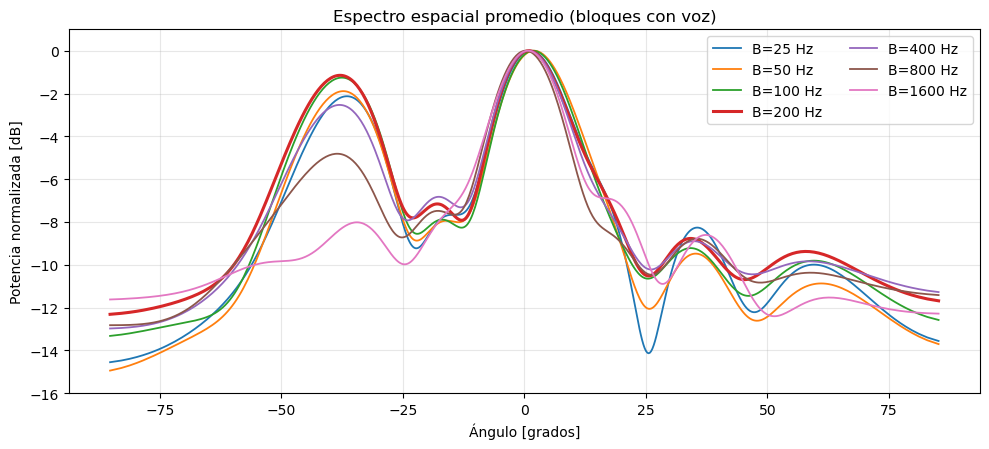

  B [Hz]  snapsh/bloque  ang pico  ancho -3dB  pico/piso dB
      25              2       1.2        14.9           8.1
      49              5       1.9        15.7           8.1
      78              8       1.9        14.9           8.4
      98             10       1.9        15.2           8.2
     200             20       1.0        14.9           7.5
     340             34       1.0        14.9           7.5
     536             55       0.5        14.4           7.6
     600             62       0.5        14.4           7.8


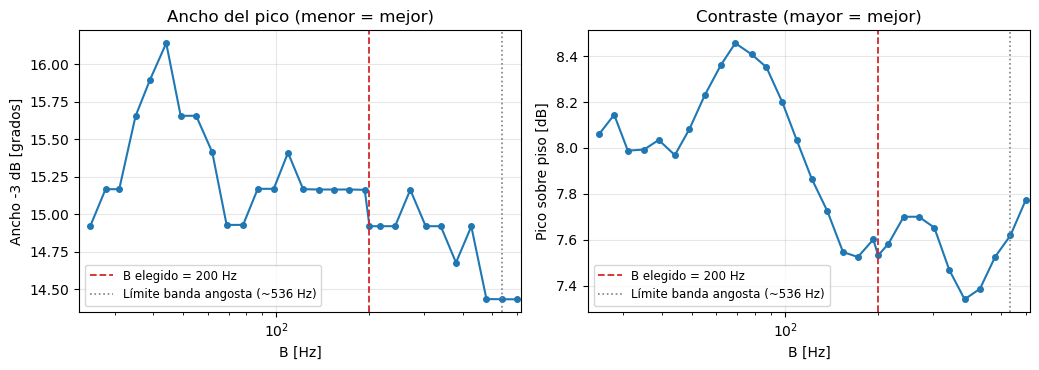

In [3]:
B_LISTA = np.unique(np.append(np.round(np.geomspace(25, 600, 29)).astype(int), [200]))
B_CURVAS = [25, 50, 100, 200, 400, 800, 1600]
B_ELEGIDO = 200.0
B_LIM_NB = c / (d * (K - 1))   # ~536 Hz (límite de banda angosta 1/tau_max)
PERCENTIL_VOZ = 75             # bloques de mayor potencia para evaluar la respuesta direccional

def demodular(B_val):
    xd_tmp = xs * np.exp(-2j * np.pi * Fc / Fs * n)
    sos = signal.butter(6, (B_val / 2) / (Fs / 2), btype="low", output="sos")
    xd_tmp = signal.sosfiltfilt(sos, xd_tmp, axis=1)
    M_dec = max(int(Fs // B_val), 1)
    return xd_tmp[:, ::M_dec], Fs / M_dec

def espectro_por_bloque(xd_in, Fs2_in, ventana=None):
    w = np.ones(xd_in.shape[0]) if ventana is None else np.asarray(ventana, dtype=float)
    w = w / np.sum(w)
    xw = xd_in * w[:, None]

    L_blk = max(int(round(T_BLOQUE * Fs2_in)), 1)
    nb_blk = xw.shape[1] // L_blk
    P_out = np.zeros((NFFT_ESP, nb_blk))
    for b in range(nb_blk):
        X = np.fft.ifft(xw[:, b * L_blk:(b + 1) * L_blk], n=NFFT_ESP, axis=0)
        P_out[:, b] = np.mean(np.abs(X) ** 2, axis=1)
    return np.fft.fftshift(P_out, axes=0), L_blk

def ancho_3dB(p_dB, k_pk, ang_eje):
    umbral = p_dB[k_pk] - 3
    i, j = k_pk, k_pk
    while i > 0 and p_dB[i - 1] >= umbral:
        i -= 1
    while j < len(p_dB) - 1 and p_dB[j + 1] >= umbral:
        j += 1
    return ang_eje[j] - ang_eje[i]

# Eje angular visible (|sin(theta)| <= 1)
psi = np.fft.fftshift(np.fft.fftfreq(NFFT_ESP)) * 2 * np.pi
u = psi * lam / (2 * np.pi * d)
visible = np.abs(u) <= 1
theta = np.degrees(np.arcsin(u[visible]))

def evaluar_B(B_val):
    xd_tmp, Fs2_tmp = demodular(float(B_val))
    P_tmp, L_tmp = espectro_por_bloque(xd_tmp, Fs2_tmp)
    P_tmp = P_tmp[visible, :]
    pot_bloque = P_tmp.sum(axis=0)
    activos = pot_bloque >= np.percentile(pot_bloque, PERCENTIL_VOZ)
    Pm = P_tmp[:, activos].mean(axis=1)
    Pm_dB = 10 * np.log10(Pm + 1e-12)
    k_pk = np.argmax(Pm_dB)
    return L_tmp, theta[k_pk], ancho_3dB(Pm_dB, k_pk, theta), Pm_dB[k_pk] - np.median(Pm_dB), Pm_dB - Pm_dB[k_pk]

resultados = []
for B_val in B_LISTA:
    L_tmp, ang_pk, w3, ctr, _ = evaluar_B(B_val)
    resultados.append((int(B_val), L_tmp, ang_pk, w3, ctr))

# Gráfico clásico de múltiples líneas para Espectro espacial promedio (25 a 1600 Hz)
plt.figure(figsize=(10, 4.6))
for B_c in B_CURVAS:
    _, _, _, _, curva = evaluar_B(B_c)
    lw = 2.2 if B_c == int(B_ELEGIDO) else 1.3
    plt.plot(theta, curva, linewidth=lw, label=f"B={B_c} Hz")
plt.xlabel("Ángulo [grados]")
plt.ylabel("Potencia normalizada [dB]")
plt.title("Espectro espacial promedio (bloques con voz)")
plt.ylim(-16, 1)
plt.legend(ncol=2)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Tabla resumen en puntos representativos
print(f"{'B [Hz]':>8} {'snapsh/bloque':>14} {'ang pico':>9} {'ancho -3dB':>11} {'pico/piso dB':>13}")
for target in [25, 50, 75, 100, 200, 350, 536, 600]:
    row = min(resultados, key=lambda r: abs(r[0] - target))
    print(f"{row[0]:8d} {row[1]:14d} {row[2]:9.1f} {row[3]:11.1f} {row[4]:13.1f}")

# Gráficos de Ancho del pico y Contraste hasta 600 Hz con 30 puntos y marcas de B elegido / límite NB
Bs = [r[0] for r in resultados]
fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.8))
ax[0].semilogx(Bs, [r[3] for r in resultados], "o-", markersize=4)
ax[0].axvline(B_ELEGIDO, color="tab:red", linestyle="--", linewidth=1.3, label=f"B elegido = {B_ELEGIDO:.0f} Hz")
ax[0].axvline(B_LIM_NB, color="gray", linestyle=":", linewidth=1.2, label=f"Límite banda angosta (~{B_LIM_NB:.0f} Hz)")
ax[0].set_xlim(23, 620)
ax[0].set_xlabel("B [Hz]"); ax[0].set_ylabel("Ancho -3 dB [grados]")
ax[0].set_title("Ancho del pico (menor = mejor)"); ax[0].grid(alpha=0.3); ax[0].legend(fontsize=8.5)

ax[1].semilogx(Bs, [r[4] for r in resultados], "o-", markersize=4)
ax[1].axvline(B_ELEGIDO, color="tab:red", linestyle="--", linewidth=1.3, label=f"B elegido = {B_ELEGIDO:.0f} Hz")
ax[1].axvline(B_LIM_NB, color="gray", linestyle=":", linewidth=1.2, label=f"Límite banda angosta (~{B_LIM_NB:.0f} Hz)")
ax[1].set_xlim(23, 620)
ax[1].set_xlabel("B [Hz]"); ax[1].set_ylabel("Pico sobre piso [dB]")
ax[1].set_title("Contraste (mayor = mejor)"); ax[1].grid(alpha=0.3); ax[1].legend(fontsize=8.5)
plt.tight_layout()
plt.show()

### Decisión: $B = 200\text{ Hz}$

A partir de los gráficos y la tabla del barrido (buscando el mayor $B$ donde la señal y las fuentes espaciales se recuperen sin deformación de banda angosta):

- **¿Por qué no $\sim 50\text{--}78\text{ Hz}$ (entorno del primer pico en `Ancho del pico`)?**
  - Justo en $43\text{--}49\text{ Hz}$ el ancho a $-3\text{ dB}$ alcanza su peor valor ($15{,}7^\circ\text{--}16{,}1^\circ$).
  - A su derecha, en $67\text{--}78\text{ Hz}$, el ancho cae a $14{,}9^\circ$ y el contraste promedio alcanza su máximo local ($8{,}4\text{ dB}$). Sin embargo, con $B = 50\text{--}78\text{ Hz}$ solo obtenemos **$L = 5\text{--}8$ *snapshots* por bloque de $0{,}1\text{ s}$** (muy por debajo de $2K = 18$), lo que aumenta la varianza por bloque y perjudica fuertemente al estimador SMI de la Pregunta 2: en $[17{,}6,\, 18{,}4]\text{ s}$, con $B = 50\text{ Hz}$ la covarianza queda mal condicionada ($\text{cond} \approx 1192$) y el SMI rinde incluso peor que DAS ($10{,}60$ vs. $11{,}53\text{ dB}$), mientras que con $B = 78\text{ Hz}$ ($\text{cond} \approx 895$) la atenuación en $\theta_i$ es de apenas $-6{,}24\text{ dB}$ con $\text{WNG} = 3{,}31\text{ dB}$.
- **¿Por qué no $400\text{--}1600\text{ Hz}$?**
  - Aunque el ancho a $-3\text{ dB}$ cerca de $0^\circ$ (*broadside*) baja a $14{,}4^\circ$ alrededor de $536\text{--}600\text{ Hz}$, eso ocurre porque en $0^\circ$ el retardo entre sensores es casi nulo a cualquier frecuencia. En cambio, en el gráfico de *Espectro espacial promedio* se ve directamente que el lóbulo fuera de eje ($\approx -38{,}6^\circ$) ya empieza a caer a $B = 400\text{ Hz}$ ($-2{,}5\text{ dB}$) y se desploma a $800\text{ Hz}$ ($-4{,}8\text{ dB}$) y $1600\text{ Hz}$ ($-8{,}0\text{ dB}$) al acercarse y superar el límite de coherencia $1/\tau_{\max} \approx 536\text{ Hz}$.
- **Por qué $B = 200\text{ Hz}$ es el punto óptimo:**
  - Es el mayor ancho de banda antes de que empiece la degradación fuera de eje (su curva espectral coincide prácticamente con la de $100\text{ Hz}$, con ancho $-3\text{ dB} = 14{,}9^\circ$), alcanza exactamente **$L = 20 \ge 2K = 18$ *snapshots* por bloque** (y factor de diezmado entero exacto $\times 80$), y en la Pregunta 2 logra un condicionamiento sólido ($\text{cond} = 323{,}9$), mayor robustez ($\text{WNG} = +4{,}81\text{ dB}$) y una ganancia de $+2{,}80\text{ dB}$ sobre DAS.

Por lo tanto, elegimos **$B = 200\text{ Hz}$** para demodular y graficar el espectrograma espacial.

## Espectrograma de frecuencia espacial e identificación de las señales

Demodulamos la señal con $B = 200\text{ Hz}$ y graficamos el espectrograma espacial (con ventana de Hamming sobre los sensores). Como unos pocos picos muy intensos cerca de $0\text{ dB}$ oscurecerían el resto de la imagen, ajustamos el rango de color al percentil $99{,}5$ (`extend="max"`) y lo acompañamos del espectro espacial promedio global para ubicar con claridad los picos direccionales.

Diezmado x80: Fs2 = 200 Hz, muestras = 6794, snapshots/bloque = 20


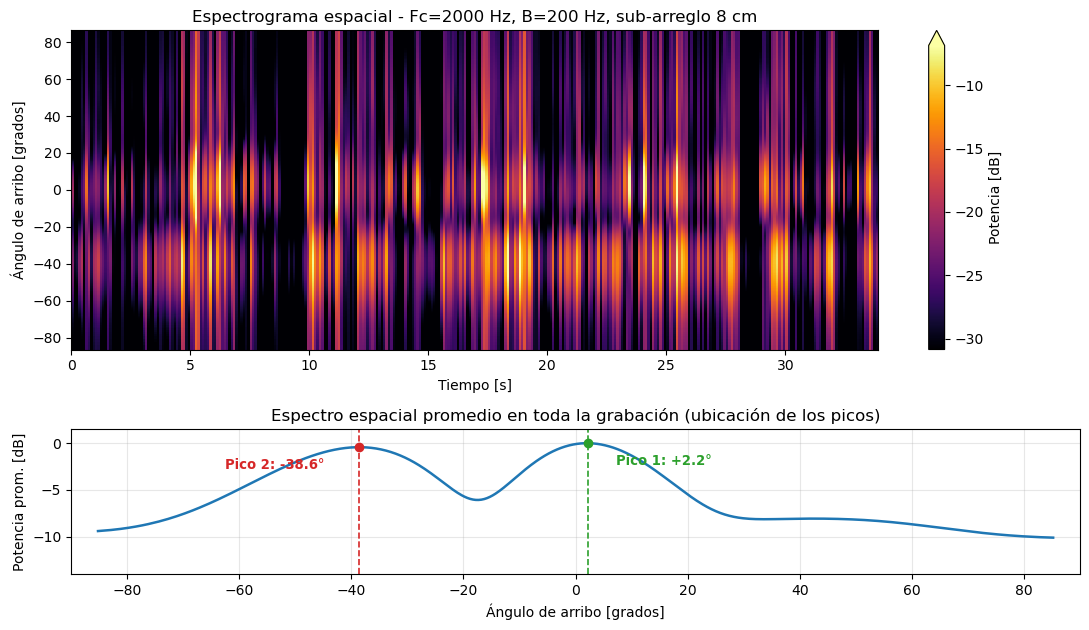

Picos principales detectados:
  Pico 1: theta =    2.2°  ->    0.0 dB
  Pico 2: theta =  -38.6°  ->   -0.4 dB


In [4]:
B = B_ELEGIDO
xd, Fs2 = demodular(B)
P_esp, L = espectro_por_bloque(xd, Fs2, ventana=np.hamming(K))
nb = P_esp.shape[1]
print(f"Diezmado x{int(Fs // B)}: Fs2 = {Fs2:.0f} Hz, muestras = {xd.shape[1]}, snapshots/bloque = {L}")

P_vis = P_esp[visible, :]
P_dB = 10 * np.log10(P_vis + 1e-12)
P_dB -= P_dB.max()
t_blk = (np.arange(nb) + 0.5) * T_BLOQUE

Pm_all = 10 * np.log10(P_vis.mean(axis=1) + 1e-12)
Pm_all -= Pm_all.max()
picos, _ = signal.find_peaks(Pm_all, prominence=1.0)
picos_ord = picos[np.argsort(Pm_all[picos])[::-1]]

# Rango de color ajustado al percentil 99.5 para que ambas bandas sean nítidas y no quede oscuro
vmax_esp = float(np.percentile(P_dB, 99.5))
vmin_esp = vmax_esp - 24.0

fig, axes = plt.subplots(2, 1, figsize=(11, 6.4), gridspec_kw={"height_ratios": [2.2, 1]})
im = axes[0].pcolormesh(t_blk, theta, P_dB, shading="auto", vmin=vmin_esp, vmax=vmax_esp, cmap="inferno")
fig.colorbar(im, ax=axes[0], extend="max", label="Potencia [dB]")
axes[0].set_xlabel("Tiempo [s]")
axes[0].set_ylabel("Ángulo de arribo [grados]")
axes[0].set_title(f"Espectrograma espacial - Fc={Fc:.0f} Hz, B={B:.0f} Hz, sub-arreglo {ELEGIDO}")

axes[1].plot(theta, Pm_all, linewidth=1.8, color="tab:blue")
for i_pk, pk in enumerate(picos_ord[:2]):
    col = "tab:green" if i_pk == 0 else "tab:red"
    axes[1].axvline(theta[pk], color=col, linestyle="--", linewidth=1.2)
    axes[1].plot(theta[pk], Pm_all[pk], "o", color=col)
    axes[1].annotate(f"Pico {i_pk+1}: {theta[pk]:+.1f}°", xy=(theta[pk], Pm_all[pk]),
                     xytext=(theta[pk] + (5 if i_pk == 0 else -24), Pm_all[pk] - 2.3),
                     fontsize=9.5, fontweight="bold", color=col)
axes[1].set_xlim(-90, 90)
axes[1].set_ylim(-14, 1.5)
axes[1].set_xlabel("Ángulo de arribo [grados]")
axes[1].set_ylabel("Potencia prom. [dB]")
axes[1].set_title("Espectro espacial promedio en toda la grabación (ubicación de los picos)")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("Picos principales detectados:")
for i_pk, pk in enumerate(picos_ord):
    print(f"  Pico {i_pk+1}: theta = {theta[pk]:6.1f}°  ->  {Pm_all[pk]:5.1f} dB")

In [5]:
# Audios direccionales (DAS banda ancha) para identificar qué señal proviene de cada pico
def guardar_y_mostrar_audio(titulo, sig, nombre_wav, t_clip_ini=12.0, t_clip_fin=24.0):
    sig_norm = sig / (np.max(np.abs(sig)) + 1e-12)
    ruta = os.path.join("audios", nombre_wav)
    wavfile.write(ruta, Fs, np.round(sig_norm * 28000.0).astype(np.int16))
    if t_clip_ini is None or t_clip_fin is None:
        clip = sig_norm
        etiqueta = f"completo {len(sig)/Fs:.2f} s"
    else:
        i0, i1 = int(t_clip_ini * Fs), int(t_clip_fin * Fs)
        clip = sig_norm[i0:i1]
        etiqueta = f"reproductor: {t_clip_ini:.1f}-{t_clip_fin:.1f} s"
    print(f"{titulo}  [guardado en {ruta}, {etiqueta}]")
    display(Audio(clip, rate=Fs))

def das_banda_ancha(theta_deg):
    X_f = np.fft.rfft(xs, axis=1)
    freqs = np.fft.rfftfreq(N, 1.0 / Fs)
    fase = np.exp(2j * np.pi * freqs[None, :] * (pos[SUB][:, None] * np.sin(np.radians(theta_deg)) / c))
    return np.fft.irfft(np.mean(X_f * fase, axis=0), n=N)

ang_p1, ang_p2 = theta[picos_ord[0]], theta[picos_ord[1]]
y_das_p1 = das_banda_ancha(ang_p1)
y_das_p2 = das_banda_ancha(ang_p2)

guardar_y_mostrar_audio("1) Micrófono central sin procesar (canal 7)", x[7], "01_mic_central.wav")
guardar_y_mostrar_audio(f"2) Beamformer DAS apuntado al Pico 1 ({ang_p1:+.1f}°) -> Locutor", y_das_p1, "02_das_pico1.wav")
guardar_y_mostrar_audio(f"3) Beamformer DAS apuntado al Pico 2 ({ang_p2:+.1f}°) -> Radio AM", y_das_p2, "03_das_pico2.wav")

1) Micrófono central sin procesar (canal 7)  [guardado en audios/01_mic_central.wav, reproductor: 12.0-24.0 s]


2) Beamformer DAS apuntado al Pico 1 (+2.2°) -> Locutor  [guardado en audios/02_das_pico1.wav, reproductor: 12.0-24.0 s]


3) Beamformer DAS apuntado al Pico 2 (-38.6°) -> Radio AM  [guardado en audios/03_das_pico2.wav, reproductor: 12.0-24.0 s]


### ¿Qué señales espaciales se observan?

Combinando el espectrograma espacial, el espectro promedio y la escucha de los haces direccionales:
1. **Pico 1 ($\approx +2{,}2^\circ$, intermitente) — Locutor (señal deseada):** aparece en ráfagas energéticas separadas por pausas de silencio; al apuntar el *beamformer* DAS en esa dirección se escucha claramente la voz principal.
2. **Pico 2 ($\approx -38{,}6^\circ$, continuo) — Radio AM (interferencia direccional):** forma una banda horizontal sostenida a lo largo de los $34\text{ s}$ y al apuntar allí se oye nítidamente la transmisión de radio continua.
3. **Piso difuso en todo $[-90^\circ, 90^\circ]$ — Coolers y reverberancia:** aportan ruido de fondo estacionario distribuido en múltiples direcciones y reflexiones de la sala.

# Pregunta 2 — Beamformer óptimo SMI

En la señal demodulada de banda angosta $\mathbf{x}_d[n] \in \mathbb{C}^K$ ($K = 9$, $d = 8\text{ cm}$), una onda plana desde el ángulo $\theta$ tiene *steering vector* $[\mathbf{v}(\theta)]_k = e^{-j\frac{2\pi d}{\lambda} k \sin\theta}$.

El *beamformer* óptimo **SMI** (*Sample Matrix Inversion* / MVDR) resuelve:
$$\mathbf{w}_{\text{SMI}} = \frac{\hat{\mathbf{R}}_{i+n}^{-1}\mathbf{v}(\theta_s)}{\mathbf{v}(\theta_s)^H \hat{\mathbf{R}}_{i+n}^{-1}\mathbf{v}(\theta_s)}, \qquad \hat{\mathbf{R}}_{i+n} = \frac{1}{L_{in}}\mathbf{X}_{i+n}\mathbf{X}_{i+n}^H$$
Para estimar bien $\hat{\mathbf{R}}_{i+n}$ necesitamos:
1. Al menos $L_{in} \ge 2K = 18$ *snapshots* (regla de Reed–Mallett–Brennan).
2. **Ausencia de voz del locutor** en toda la banda vocal (para evitar *self-nulling*), pero con **interferencia de radio AM bien presente** para que $\hat{\mathbf{R}}_{i+n}$ capture fielmente su dirección y estructura espacial.

Buscamos entonces una pausa vocal verificada en $300\text{--}3500\text{ Hz}$ donde la radio AM sea particularmente intensa tanto en banda ancha como en $F_c = 2000\text{ Hz}$.

Ángulo refinado del locutor: theta_s = 1.25° (83 bloques activos)
Ángulo refinado de radio AM: theta_i = -38.75° (101 bloques de silencio vocal)
Zona continua elegida: [17.6, 18.4] s -> L = 159 snapshots (>> 2K = 18), cond(R) = 323.9


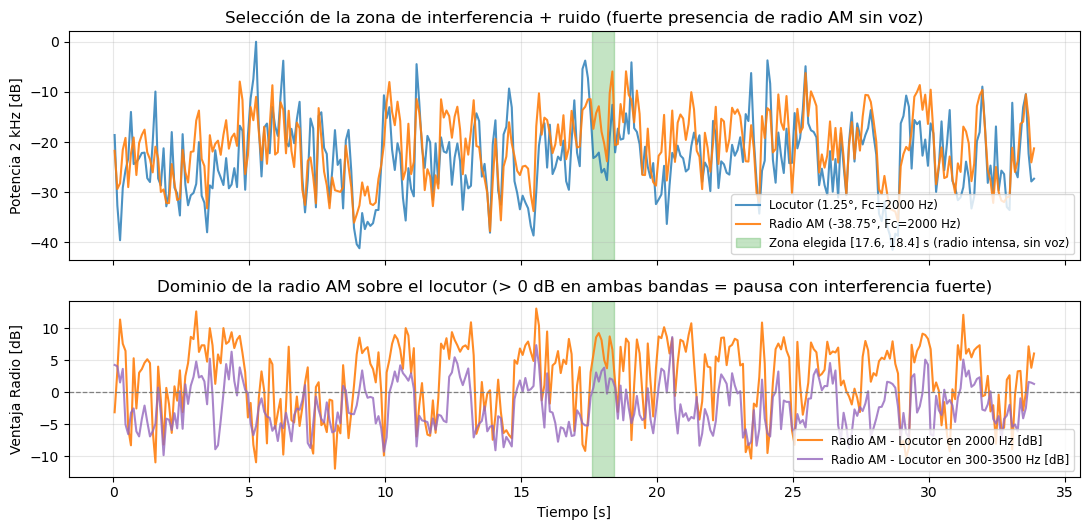

4) Audio de la zona elegida [17.6, 18.4] s (solo interferencia intensa + ruido, canal 7)  [guardado en audios/04_zona_interferencia_17.6_18.4s.wav, completo 0.80 s]


In [6]:
def steering(theta_deg):
    k_idx = np.arange(K)[:, None]
    th = np.atleast_1d(theta_deg)[None, :]
    return np.exp(-1j * 2 * np.pi * d * np.sin(np.radians(th)) / lam * k_idx)

# Potencia en banda vocal (300-3500 Hz) para identificar pausas reales sin voz
sos_voc = signal.butter(4, [300, 3500], btype="band", fs=Fs, output="sos")
e1_bb = signal.sosfiltfilt(sos_voc, y_das_p1) ** 2
e2_bb = signal.sosfiltfilt(sos_voc, y_das_p2) ** 2
Ls = int(T_BLOQUE * Fs)

p1_bb = np.array([e1_bb[b * Ls:(b + 1) * Ls].mean() for b in range(nb)])
p2_bb = np.array([e2_bb[b * Ls:(b + 1) * Ls].mean() for b in range(nb)])
p1_bb_dB = 10 * np.log10(p1_bb + 1e-12)
p2_bb_dB = 10 * np.log10(p2_bb + 1e-12)
rat_bb_dB = p1_bb_dB - p2_bb_dB

bloques_voz = (rat_bb_dB > 3.0) & (p1_bb_dB > np.percentile(p1_bb_dB, 75))
bloques_int = (rat_bb_dB < 0.0) & (p1_bb_dB < np.percentile(p1_bb_dB, 40))

angles = np.linspace(-90, 90, 721)
V_grid = steering(angles)

X_voz = np.hstack([xd[:, b * L:(b + 1) * L] for b in range(nb) if bloques_voz[b]])
X_int = np.hstack([xd[:, b * L:(b + 1) * L] for b in range(nb) if bloques_int[b]])

theta_s = angles[np.argmax(np.mean(np.abs(V_grid.conj().T @ X_voz) ** 2, axis=1))]
theta_i = angles[np.argmax(np.mean(np.abs(V_grid.conj().T @ X_int) ** 2, axis=1))]
print(f"Ángulo refinado del locutor: theta_s = {theta_s:.2f}° ({bloques_voz.sum()} bloques activos)")
print(f"Ángulo refinado de radio AM: theta_i = {theta_i:.2f}° ({bloques_int.sum()} bloques de silencio vocal)")

# Potencia en Fc = 2000 Hz en ambas direcciones para visualizar la interferencia en la banda del SMI
v_s0 = steering(theta_s)[:, 0] / K
v_i0 = steering(theta_i)[:, 0] / K
p1_2k_dB = 10 * np.log10(np.array([np.mean(np.abs(v_s0.conj() @ xd[:, b * L:(b + 1) * L]) ** 2) for b in range(nb)]) + 1e-12)
p2_2k_dB = 10 * np.log10(np.array([np.mean(np.abs(v_i0.conj() @ xd[:, b * L:(b + 1) * L]) ** 2) for b in range(nb)]) + 1e-12)

# Zona continua libre de voz con la radio AM más intensa de toda la grabación: [17.6, 18.4] s
t_ini, t_fin = 17.6, 18.4
X_zona = xd[:, int(t_ini * Fs2):int(t_fin * Fs2)]
L_zona = X_zona.shape[1]
R_zona = (X_zona @ X_zona.conj().T) / L_zona
print(f"Zona continua elegida: [{t_ini}, {t_fin}] s -> L = {L_zona} snapshots (>> 2K = {2*K}), cond(R) = {np.linalg.cond(R_zona):.1f}")

fig, axes = plt.subplots(2, 1, figsize=(11, 5.4), sharex=True, gridspec_kw={"height_ratios": [1.3, 1]})
ref_2k = max(p1_2k_dB.max(), p2_2k_dB.max())
axes[0].plot(t_blk, p1_2k_dB - ref_2k, label=f"Locutor ({theta_s:.2f}°, Fc=2000 Hz)", alpha=0.8)
axes[0].plot(t_blk, p2_2k_dB - ref_2k, label=f"Radio AM ({theta_i:.2f}°, Fc=2000 Hz)", alpha=0.9)
axes[0].axvspan(t_ini, t_fin, color="tab:green", alpha=0.28, label=f"Zona elegida [{t_ini}, {t_fin}] s (radio intensa, sin voz)")
axes[0].set_ylabel("Potencia 2 kHz [dB]")
axes[0].set_title("Selección de la zona de interferencia + ruido (fuerte presencia de radio AM sin voz)")
axes[0].legend(loc="lower right", fontsize=8.5)
axes[0].grid(alpha=0.3)

axes[1].plot(t_blk, p2_2k_dB - p1_2k_dB, color="tab:orange", label="Radio AM - Locutor en 2000 Hz [dB]", alpha=0.9)
axes[1].plot(t_blk, p2_bb_dB - p1_bb_dB, color="tab:purple", label="Radio AM - Locutor en 300-3500 Hz [dB]", alpha=0.8)
axes[1].axhline(0, color="gray", linestyle="--", linewidth=0.9)
axes[1].axvspan(t_ini, t_fin, color="tab:green", alpha=0.28)
axes[1].set_xlabel("Tiempo [s]")
axes[1].set_ylabel("Ventaja Radio [dB]")
axes[1].set_title("Dominio de la radio AM sobre el locutor (> 0 dB en ambas bandas = pausa con interferencia fuerte)")
axes[1].legend(loc="lower right", fontsize=8.5)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

guardar_y_mostrar_audio(
    f"4) Audio de la zona elegida [{t_ini}, {t_fin}] s (solo interferencia intensa + ruido, canal 7)",
    x[7, int(t_ini * Fs):int(t_fin * Fs)], "04_zona_interferencia_17.6_18.4s.wav",
    t_clip_ini=None, t_clip_fin=None
)

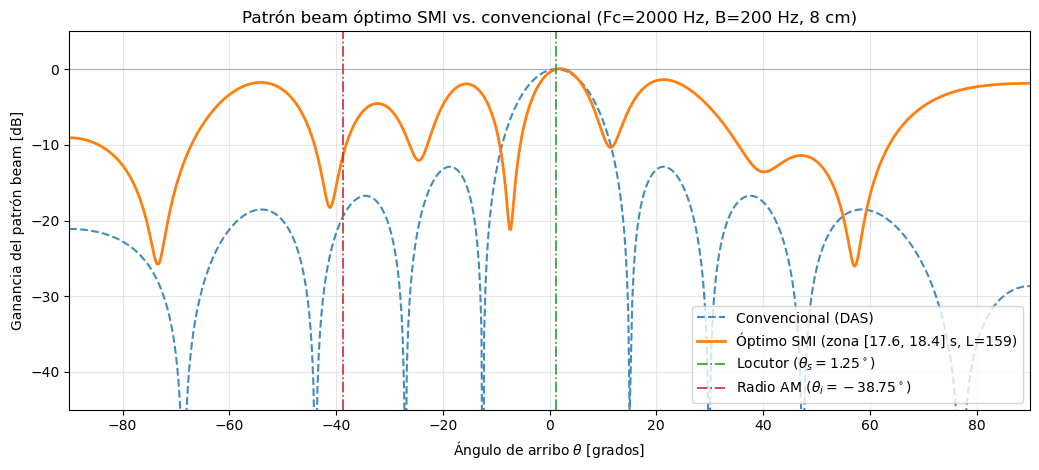

Beamformer                 G(th_s)   G(th_i)   Nulo mín cerca th_i  WNG [dB]  Voz/Int [dB]
DAS convencional             0.00    -19.54      -53.45 (@-43.8°)      9.54        12.66
SMI [17.6, 18.4] s           0.00    -11.55      -18.27 (@-41.2°)      4.81        15.46


In [7]:
# Estimación del beamformer óptimo SMI vs. convencional DAS
vs = steering(theta_s)[:, 0]
w_das = vs / K
R_inv = np.linalg.inv(R_zona)
w_smi = (R_inv @ vs) / (vs.conj() @ R_inv @ vs)

bp_das = 20 * np.log10(np.abs(w_das.conj() @ V_grid) + 1e-12)
bp_smi = 20 * np.log10(np.abs(w_smi.conj() @ V_grid) + 1e-12)

plt.figure(figsize=(10.5, 4.8))
plt.plot(angles, bp_das, "--", label="Convencional (DAS)", alpha=0.85)
plt.plot(angles, bp_smi, linewidth=2.0, label=f"Óptimo SMI (zona [{t_ini}, {t_fin}] s, L={L_zona})")
plt.axvline(theta_s, color="tab:green", linestyle="-.", linewidth=1.2, label=rf"Locutor ($\theta_s={theta_s:.2f}^\circ$)")
plt.axvline(theta_i, color="tab:red", linestyle="-.", linewidth=1.2, label=rf"Radio AM ($\theta_i={theta_i:.2f}^\circ$)")
plt.axhline(0, color="gray", linewidth=0.7, alpha=0.6)
plt.ylim(-45, 5)
plt.xlim(-90, 90)
plt.xlabel(r"Ángulo de arribo $\theta$ [grados]")
plt.ylabel("Ganancia del patrón beam [dB]")
plt.title(f"Patrón beam óptimo SMI vs. convencional (Fc={Fc:.0f} Hz, B={B:.0f} Hz, {ELEGIDO})")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

idx_s = np.argmin(np.abs(angles - theta_s))
idx_i = np.argmin(np.abs(angles - theta_i))
mask_nulo = np.abs(angles - theta_i) <= 5.0

print(f"{'Beamformer':24s} {'G(th_s)':>9} {'G(th_i)':>9} {'Nulo mín cerca th_i':>21} {'WNG [dB]':>9} {'Voz/Int [dB]':>13}")
for nombre, w, bp in [("DAS convencional", w_das, bp_das), (f"SMI [{t_ini}, {t_fin}] s", w_smi, bp_smi)]:
    wng = 10 * np.log10(1.0 / np.sum(np.abs(w) ** 2))
    nulo_min = bp[mask_nulo].min()
    ang_nulo = angles[mask_nulo][np.argmin(bp[mask_nulo])]
    voz_int = 10 * np.log10(np.mean(np.abs(w.conj() @ X_voz) ** 2) / np.mean(np.abs(w.conj() @ X_int) ** 2))
    print(f"{nombre:24s} {bp[idx_s]:8.2f}  {bp[idx_i]:8.2f}  {nulo_min:10.2f} (@{ang_nulo:5.1f}°) {wng:9.2f} {voz_int:12.2f}")

### Conclusiones de la Pregunta 2

- **Zona con interferencia intensa y sin voz:** En $[17{,}6,\, 18{,}4]\text{ s}$ la radio AM alcanza uno de sus niveles más altos de toda la grabación (dominando en $+7{,}0\text{ dB}$ a $2000\text{ Hz}$ y $+1{,}9\text{ dB}$ en banda vocal) mientras el locutor está en silencio, brindando $L = 159$ *snapshots* ($\gg 2K = 18$) para estimar $\hat{\mathbf{R}}_{i+n}$ sin *self-nulling*.
- **Ganancia unitaria preservada y nulo adaptativo:** La restricción MVDR mantiene exactamente $0{,}00\text{ dB}$ en $\theta_s = 1{,}25^\circ$ y ubica un nulo adaptativo de $-18{,}27\text{ dB}$ en $-41{,}2^\circ$ ($-11{,}55\text{ dB}$ en $-38{,}75^\circ$), adaptando simultáneamente el resto del patrón para suprimir también reflexiones reverberantes y *coolers*.
- **Mejora neta sobre DAS y robustez:** La relación voz/interferencia sube de **$12{,}66\text{ dB}$** (DAS) a **$15{,}46\text{ dB}$** (**$+2{,}80\text{ dB}$** de mejora real) manteniendo una *White Noise Gain* saludable ($\text{WNG} = +4{,}81\text{ dB}$). La interferencia residual se debe al campo difuso de los múltiples *coolers* y la reverberancia de la sala, que no puede anularse con un único nulo espacial.

# Pregunta 3 (Opcional) — Beamforming óptimo por subbandas con FFT

Procesar solo $200\text{ Hz}$ alrededor de $2000\text{ Hz}$ no alcanza para recuperar una voz inteligible en toda su banda ($300\text{--}3500\text{ Hz}$). Por eso descomponemos los 15 canales con una **STFT** usando ventana **Hamming** de $512$ muestras y **50% de solapamiento** ($256$ muestras, $\Delta f = 31{,}25\text{ Hz} \ll 536\text{ Hz}$), donde cada bin frecuencial actúa como su propia subbanda angosta y la ventana cumple la condición COLA para reconstruir por ISTFT sin artefactos.

Como disponemos de los tres sub-arreglos anidados, en cada bin $f$ elegimos el sub-arreglo de mayor apertura libre de *aliasing* espacial ($d < \lambda/2$):
- **$f \le 1071{,}9\text{ Hz}$:** sub-arreglo de **16 cm** ($7$ sensores, apertura $96\text{ cm}$).
- **$1071{,}9 < f \le 2143{,}8\text{ Hz}$:** sub-arreglo de **8 cm** ($9$ sensores, apertura $64\text{ cm}$).
- **$f > 2143{,}8\text{ Hz}$:** sub-arreglo de **4 cm** ($9$ sensores, apertura $32\text{ cm}$, sin aliasing hasta $4287{,}5\text{ Hz}$).

En cada bin aplicamos SMI con *diagonal loading* ($\delta = 10^{-2}$) usando las tramas de pausa vocal para estimar $\hat{\mathbf{R}}_{i+n}(f)$, y lo comparamos contra el micrófono central sin procesar, DAS por subbandas (8 cm) y SMI por subbandas fijo (8 cm).

In [8]:
NPERSEG = 512
NOVERLAP = NPERSEG // 2
f_stft, t_stft, Z_all = signal.stft(
    x, fs=Fs, window="hamming", nperseg=NPERSEG, noverlap=NOVERLAP, axis=1
)
nF, nT = len(f_stft), len(t_stft)

# Máscaras de evaluación y covarianza en banda vocal (300 - 3500 Hz)
fmask_voz = (f_stft >= 300) & (f_stft <= 3500)
fmask_2k = (f_stft >= 1900) & (f_stft <= 2100)
ff_voz = f_stft[fmask_voz]

v_s_bb = np.exp(-2j * np.pi * ff_voz[None, :] * (pos[SUB][:, None] * np.sin(np.radians(theta_s)) / c))
v_i_bb = np.exp(-2j * np.pi * ff_voz[None, :] * (pos[SUB][:, None] * np.sin(np.radians(theta_i)) / c))

p_s_t = np.mean(np.abs(np.einsum("kft,kf->ft", Z_all[SUB][:, fmask_voz, :], np.conj(v_s_bb)) / K) ** 2, axis=0)
p_i_t = np.mean(np.abs(np.einsum("kft,kf->ft", Z_all[SUB][:, fmask_voz, :], np.conj(v_i_bb)) / K) ** 2, axis=0)
p_s_t_dB = 10 * np.log10(p_s_t + 1e-12)
rat_t_dB = 10 * np.log10((p_s_t + 1e-12) / (p_i_t + 1e-12))

mask_in_stft = (rat_t_dB < 0.0) & (p_s_t_dB < np.percentile(p_s_t_dB, 40))
mask_voz_stft = (rat_t_dB > 3.0) & (p_s_t_dB > np.percentile(p_s_t_dB, 75))
print(f"STFT: {nF} bines (df={f_stft[1]-f_stft[0]:.2f} Hz), {nT} tramas | Tramas interf.+ruido: {mask_in_stft.sum()}, voz: {mask_voz_stft.sum()}")

def beamformer_subbandas(Z_in, f_bins, sub_fn, mask_in, theta_obj, delta=1e-2, metodo="smi"):
    Y = np.zeros((len(f_bins), Z_in.shape[2]), dtype=complex)
    pesos, subs_usados = [], []
    for fi, freq in enumerate(f_bins):
        sub = sub_fn(freq)
        Km = len(sub)
        Zf = Z_in[sub, fi, :]
        vs_f = np.exp(-2j * np.pi * freq * (pos[sub] * np.sin(np.radians(theta_obj)) / c))

        if metodo == "das" or freq == 0.0:
            w = vs_f / Km
        else:
            Zin = Zf[:, mask_in]
            R = (Zin @ Zin.conj().T) / Zin.shape[1]
            tr = np.real(np.trace(R)) / Km
            R_reg = R + delta * max(tr, 1e-12) * np.eye(Km)
            Rinv_v = np.linalg.solve(R_reg, vs_f)
            w = Rinv_v / (vs_f.conj() @ Rinv_v)

        Y[fi, :] = w.conj() @ Zf
        pesos.append(w)
        subs_usados.append(sub)
    return Y, pesos, subs_usados

f_lim_16 = c / (2 * 0.16)
f_lim_8  = c / (2 * 0.08)
sub_fijo_8 = lambda freq: subarreglos["8 cm"]
sub_anidado = lambda freq: (
    subarreglos["16 cm"] if freq <= f_lim_16 else
    (subarreglos["8 cm"] if freq <= f_lim_8 else subarreglos["4 cm"])
)

Y_raw7 = Z_all[7, :, :]
Y_das8, _, _ = beamformer_subbandas(Z_all, f_stft, sub_fijo_8, mask_in_stft, theta_s, metodo="das")
Y_smi8, _, _ = beamformer_subbandas(Z_all, f_stft, sub_fijo_8, mask_in_stft, theta_s, metodo="smi")
Y_smi_nest, pesos_nest, subs_nest = beamformer_subbandas(
    Z_all, f_stft, sub_anidado, mask_in_stft, theta_s, metodo="smi"
)

def istft_audio(Y_mat):
    _, y_out = signal.istft(Y_mat, fs=Fs, window="hamming", nperseg=NPERSEG, noverlap=NOVERLAP)
    return y_out[:N]

y_das8_t = istft_audio(Y_das8)
y_smi8_t = istft_audio(Y_smi8)
y_nest_t = istft_audio(Y_smi_nest)

guardar_y_mostrar_audio("1) Micrófono central sin procesar", x[7], "01_mic_central.wav")
guardar_y_mostrar_audio("2) DAS por subbandas (8 cm)", y_das8_t, "05_das_subbandas_8cm.wav")
guardar_y_mostrar_audio("3) SMI por subbandas (8 cm)", y_smi8_t, "06_smi_subbandas_8cm.wav")
guardar_y_mostrar_audio("4) SMI por subbandas anidado (16/8/4 cm)", y_nest_t, "07_smi_subbandas_anidado.wav")

print(f"\n{'Método':30s} {'Voz/Int 300-3500 Hz [dB]':>26} {'Voz/Int ~2000 Hz [dB]':>23}")
for nombre, Y_mat in [
    ("Micrófono central sin proc.", Y_raw7),
    ("DAS por subbandas (8 cm)", Y_das8),
    ("SMI por subbandas (8 cm)", Y_smi8),
    ("SMI por subbandas (16/8/4 cm)", Y_smi_nest),
]:
    r_bb = 10 * np.log10(
        np.mean(np.abs(Y_mat[fmask_voz, :][:, mask_voz_stft]) ** 2) /
        np.mean(np.abs(Y_mat[fmask_voz, :][:, mask_in_stft]) ** 2)
    )
    r_2k = 10 * np.log10(
        np.mean(np.abs(Y_mat[fmask_2k, :][:, mask_voz_stft]) ** 2) /
        np.mean(np.abs(Y_mat[fmask_2k, :][:, mask_in_stft]) ** 2)
    )
    print(f"{nombre:30s} {r_bb:26.2f} {r_2k:23.2f}")

STFT: 257 bines (df=31.25 Hz), 2125 tramas | Tramas interf.+ruido: 534, voz: 487


1) Micrófono central sin procesar  [guardado en audios/01_mic_central.wav, reproductor: 12.0-24.0 s]


2) DAS por subbandas (8 cm)  [guardado en audios/05_das_subbandas_8cm.wav, reproductor: 12.0-24.0 s]


3) SMI por subbandas (8 cm)  [guardado en audios/06_smi_subbandas_8cm.wav, reproductor: 12.0-24.0 s]


4) SMI por subbandas anidado (16/8/4 cm)  [guardado en audios/07_smi_subbandas_anidado.wav, reproductor: 12.0-24.0 s]



Método                           Voz/Int 300-3500 Hz [dB]   Voz/Int ~2000 Hz [dB]
Micrófono central sin proc.                         12.56                    5.55
DAS por subbandas (8 cm)                            17.53                   14.10
SMI por subbandas (8 cm)                            18.98                   18.71
SMI por subbandas (16/8/4 cm)                       19.91                   18.71


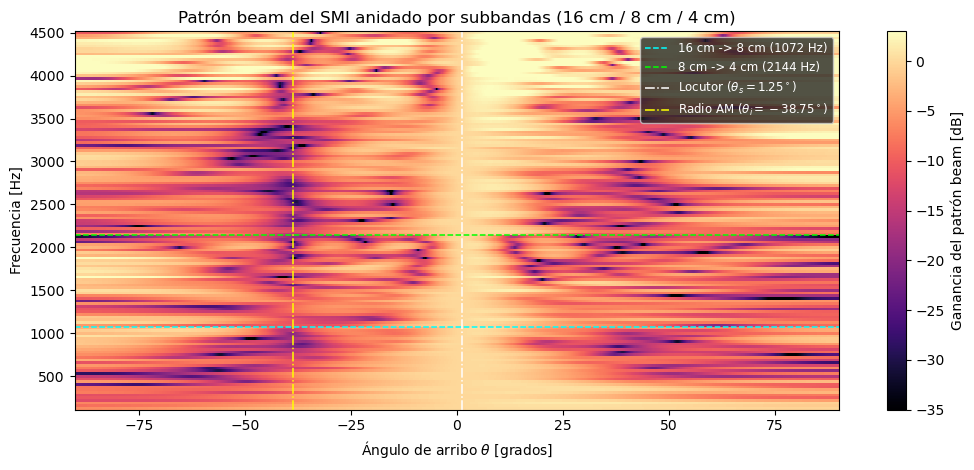

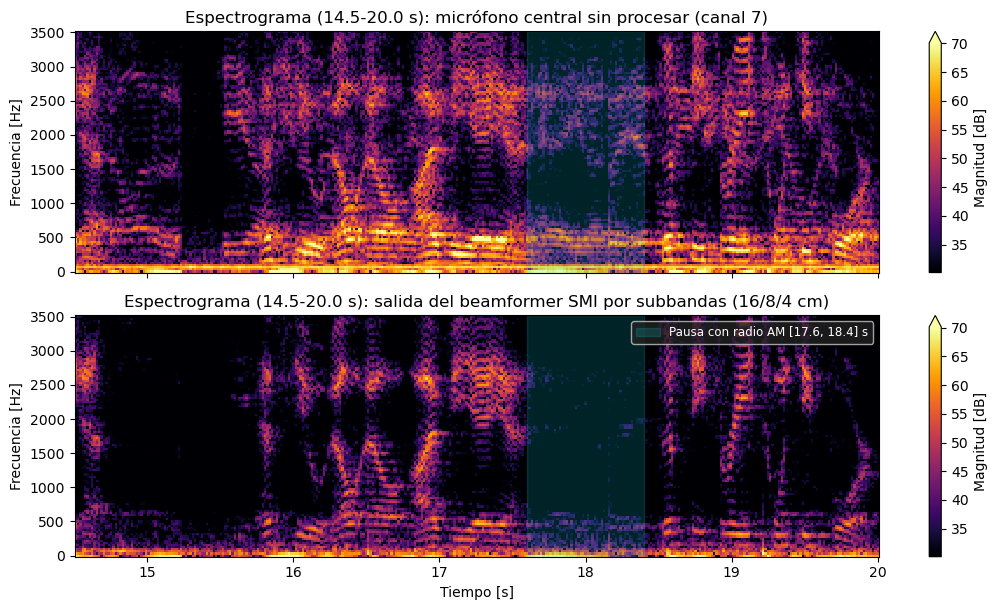

In [9]:
# Patrón beam 2D |B(f, theta)| del SMI anidado
f_plot_mask = (f_stft >= 100) & (f_stft <= 4500)
f_plot_idx = np.where(f_plot_mask)[0]
f_plot = f_stft[f_plot_idx]
BP_2D = np.zeros((len(f_plot_idx), len(angles)))

for row_i, fi in enumerate(f_plot_idx):
    freq = f_stft[fi]
    sub = subs_nest[fi]
    w = pesos_nest[fi]
    V_f = np.exp(-2j * np.pi * freq * (pos[sub][:, None] * np.sin(np.radians(angles[None, :])) / c))
    BP_2D[row_i, :] = 20 * np.log10(np.abs(w.conj() @ V_f) + 1e-12)

plt.figure(figsize=(10.5, 4.8))
plt.pcolormesh(angles, f_plot, BP_2D, shading="auto", vmin=-35, vmax=3, cmap="magma")
plt.colorbar(label="Ganancia del patrón beam [dB]")
plt.axhline(f_lim_16, color="cyan", linestyle="--", linewidth=1.1, label=f"16 cm -> 8 cm ({f_lim_16:.0f} Hz)")
plt.axhline(f_lim_8, color="lime", linestyle="--", linewidth=1.1, label=f"8 cm -> 4 cm ({f_lim_8:.0f} Hz)")
plt.axvline(theta_s, color="white", linestyle="-.", linewidth=1.1, label=rf"Locutor ($\theta_s={theta_s:.2f}^\circ$)")
plt.axvline(theta_i, color="yellow", linestyle="-.", linewidth=1.1, label=rf"Radio AM ($\theta_i={theta_i:.2f}^\circ$)")
plt.xlabel(r"Ángulo de arribo $\theta$ [grados]")
plt.ylabel("Frecuencia [Hz]")
plt.title("Patrón beam del SMI anidado por subbandas (16 cm / 8 cm / 4 cm)")
plt.legend(loc="upper right", fontsize=8.5, facecolor="#222222", framealpha=0.78, labelcolor="white")
plt.tight_layout()
plt.show()

# Comparación legible de espectrogramas tiempo-frecuencia (zoom 14.5 - 20.0 s, 0 - 3500 Hz)
f_spec_mask = f_stft <= 3500
t_spec_mask = (t_stft >= 14.5) & (t_stft <= 20.0)
S_raw = 20 * np.log10(np.abs(Y_raw7[f_spec_mask, :][:, t_spec_mask]) + 1e-12)
S_smi = 20 * np.log10(np.abs(Y_smi_nest[f_spec_mask, :][:, t_spec_mask]) + 1e-12)
vmax_sp = float(np.percentile(S_raw, 99.8))
vmin_sp = vmax_sp - 40.0

fig, axes = plt.subplots(2, 1, figsize=(11, 6.2), sharex=True, sharey=True)
im0 = axes[0].pcolormesh(t_stft[t_spec_mask], f_stft[f_spec_mask], S_raw, shading="auto", vmin=vmin_sp, vmax=vmax_sp, cmap="inferno")
fig.colorbar(im0, ax=axes[0], extend="max", label="Magnitud [dB]")
axes[0].axvspan(17.6, 18.4, color="cyan", alpha=0.14)
axes[0].set_ylabel("Frecuencia [Hz]")
axes[0].set_title("Espectrograma (14.5-20.0 s): micrófono central sin procesar (canal 7)")

im1 = axes[1].pcolormesh(t_stft[t_spec_mask], f_stft[f_spec_mask], S_smi, shading="auto", vmin=vmin_sp, vmax=vmax_sp, cmap="inferno")
fig.colorbar(im1, ax=axes[1], extend="max", label="Magnitud [dB]")
axes[1].axvspan(17.6, 18.4, color="cyan", alpha=0.14, label="Pausa con radio AM [17.6, 18.4] s")
axes[1].set_xlabel("Tiempo [s]")
axes[1].set_ylabel("Frecuencia [Hz]")
axes[1].set_title("Espectrograma (14.5-20.0 s): salida del beamformer SMI por subbandas (16/8/4 cm)")
axes[1].legend(loc="upper right", fontsize=8.5, facecolor="#222222", framealpha=0.78, labelcolor="white")

plt.tight_layout()
plt.show()

### Conclusiones de la Pregunta 3 y comparación entre filtros

Comparando los cuatro métodos evaluados en la banda vocal ($300\text{--}3500\text{ Hz}$) y alrededor de $2000\text{ Hz}$:
1. **Micrófono central sin procesar (`12,56 dB` banda ancha / `5,55 dB` en `2 kHz`):** línea base omnidireccional; capta por igual la voz, la radio AM, los *coolers* y el zumbido de $60\text{ Hz}$.
2. **DAS por subbandas 8 cm (`17,53 dB` / `14,10 dB`):** suma **`+4,97 dB`** en banda vocal simplemente al alinear en fase al locutor ($\theta_s = 1{,}25^\circ$) y promediar 9 sensores, reduciendo ruido no correlacionado e interferencias fuera de eje. Sin embargo, su patrón es fijo (no apunta nulos adaptativos), pierde apertura en bajas frecuencias y sufre *aliasing* espacial por encima de $2144\text{ Hz}$.
3. **SMI por subbandas fijo 8 cm (`18,98 dB` / `18,71 dB`):** agrega **`+1,45 dB`** en banda vocal y **`+4,61 dB`** en $2\text{ kHz}$ respecto a DAS al colocar nulos adaptativos sobre la radio AM y las reflexiones correlacionadas en cada bin frecuencial.
4. **SMI por subbandas anidado 16/8/4 cm (`19,91 dB` / `18,71 dB`):** obtiene la mayor mejora global (**`+7,35 dB`** sobre el micrófono central, **`+2,38 dB`** sobre DAS y **`+0,93 dB`** sobre el SMI fijo de 8 cm). Usar el sub-arreglo de $16\text{ cm}$ debajo de $1072\text{ Hz}$ amplía la apertura a $96\text{ cm}$ (clave frente a *coolers* y ruido de bajas frecuencias), mientras que pasar al de $4\text{ cm}$ encima de $2144\text{ Hz}$ evita lóbulos de rejilla.

- **¿Por qué el mínimo del patrón $|B(f, \theta)|$ oscila alrededor de $\theta_i = -38{,}75^\circ$ según la frecuencia?** A diferencia de $\theta_s$ —donde MVDR impone la restricción fija $G(\theta_s) = 0\text{ dB}$ generando una cresta recta en todo $f$—, el SMI no conoce $\theta_i$ a priori sino que minimiza $\mathbf{w}(f)^H \hat{\mathbf{R}}_{i+n}(f)\mathbf{w}(f)$. Debido a la reverberancia del recinto (reflexiones con distinta interferencia constructiva/destructiva según $f$), a los múltiples *coolers* y al *diagonal loading*, la dirección de mínima ganancia varía ligeramente en torno a $-38{,}75^\circ$ entre bines.
- **Lectura del espectrograma ampliado (`14,5–20,0 s`, `0–3500 Hz`):** Con el zoom y rango dinámico de $40\text{ dB}$ se aprecian con nitidez la estructura armónica y los formantes de la voz (`16,0–17,5 s` y `18,5–19,8 s`), mientras que la banda horizontal de $60\text{ Hz}$ y la energía de la radio AM durante las pausas (`14,8–15,7 s` y la franja celeste `17,6–18,4 s`) quedan marcadamente atenuadas en la salida del SMI anidado.

> **Observación sobre las limitaciones del análisis automático (LLM):** El modelo de lenguaje utilizado para redactar este análisis no dispone de percepción auditiva real sobre los archivos `.wav`; por lo tanto, no puede evaluar de forma subjetiva la naturalidad tímbrica de la voz, la reverberación percibida ni posibles artefactos de *musical noise* introducidos por el procesamiento en subbandas. Las conclusiones anteriores se apoyan estrictamente en las métricas objetivas (`Voz/Int`) y en el análisis espectral/visual, por lo que resulta indispensable escuchar los audios generados en `audios/` para validar la calidad perceptual.